In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
import os
from dotenv import load_dotenv 
from langgraph.checkpoint.memory import MemorySaver

In [2]:
load_dotenv()

True

In [3]:
model = ChatGoogleGenerativeAI(
     model="gemini-3.8-flash",
    google_api_key=os.getenv("GOOGLE_API_KEY"),
    temperature=0
)

In [4]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):

    messages: Annotated[list[BaseMessage], add_messages]

In [5]:
def chat_node(state: ChatState):
    messages = state['messages']

    ## Invoke llm
    response =  model.invoke(messages)

    # response store state
    return {'messages': [response]}

In [6]:
checkpoint = MemorySaver()
thread_id = 1

graph = StateGraph(ChatState)

graph.add_node("chat_node", chat_node)

graph.add_edge(START, "chat_node")
graph.add_edge("chat_node", END)

chatbot = graph.compile(checkpointer=checkpoint)

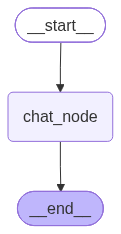

In [7]:
chatbot

In [8]:
initial_state = {
    'messages': [
        HumanMessage(
            content = "What is a Apple?"
        )
    ]
}

config = {"configurable": {"thread_id": "thread_id"}}
response = chatbot.invoke(initial_state, config=config)

In [9]:
response['messages'][-1].content

[{'type': 'text',
  'text': 'The word **apple** usually refers to one of two things: the **fruit** or the **technology company**.\n\n---\n\n### 1. The Fruit\nAn apple is a round, edible fruit produced by an apple tree (*Malus domestica*), which belongs to the rose family (*Rosaceae*).\n* **Characteristics:** It typically has red, green, or yellow skin, with crisp, juicy, whitish flesh inside and a core containing seeds.\n* **Taste:** Ranges from sweet (like Fuji or Gala) to tart (like Granny Smith).\n* **Nutrition:** High in dietary fiber, vitamin C, and antioxidants.\n* **Uses:** Eaten raw, baked into desserts (like apple pie), or pressed into juice and cider.\n\n---\n\n### 2. The Technology Company (Apple Inc.)\n**Apple Inc.** is one of the world\'s largest multinational technology companies, headquartered in Cupertino, California.\n* **History:** Founded on April 1, 1976, by **Steve Jobs, Steve Wozniak, and Ronald Wayne**.\n* **Famous Products:** \n  * **Hardware:** iPhone, iPad, Ma

In [10]:

while True:
    user_message = input('Type here: ')

    print("User: ", user_message)

    if user_message.strip().lower() in ['exit', 'quit', 'bye']:
        break

    if user_message == "":
        break

    config = {'configurable': {'thread_id': thread_id}}
    response = chatbot.invoke({'messages' : [HumanMessage(content = user_message)]}, config = config)
    
    print("Model returned.")
    print('AI: ', response['messages'][-1].content)


User:  


In [11]:
chatbot.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='What is a Apple?', additional_kwargs={}, response_metadata={}, id='acaf0da3-1820-41dd-85c1-9bfcc2ae2d6d'), AIMessage(content=[{'type': 'text', 'text': 'The word **apple** usually refers to one of two things: the **fruit** or the **technology company**.\n\n---\n\n### 1. The Fruit\nAn apple is a round, edible fruit produced by an apple tree (*Malus domestica*), which belongs to the rose family (*Rosaceae*).\n* **Characteristics:** It typically has red, green, or yellow skin, with crisp, juicy, whitish flesh inside and a core containing seeds.\n* **Taste:** Ranges from sweet (like Fuji or Gala) to tart (like Granny Smith).\n* **Nutrition:** High in dietary fiber, vitamin C, and antioxidants.\n* **Uses:** Eaten raw, baked into desserts (like apple pie), or pressed into juice and cider.\n\n---\n\n### 2. The Technology Company (Apple Inc.)\n**Apple Inc.** is one of the world\'s largest multinational technology companies, headquartered 